# 第4章：ONC vs skfolio 层次聚类

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed, quiet

SEED = 42
RUN_EXPENSIVE = False
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 算法区别与搜索预算
[原ONC](Machine_Learning_for_Asset_Managers/ch4_optimal_clustering.py)把距离矩阵的每一行当成KMeans特征，
内部轮廓系数也按这些行向量之间的欧氏距离计算。skfolio层次聚类直接使用成对角距离。
两者目标和几何口径不同：最终统一在**原始预计算角距离**上评分，另列ONC内部指标。
ONC最大搜索簇数20，保留原函数默认10次外层初始化和内部KMeans的10次初始化；
Top函数还会递归。全量可能耗时，日志显示阶段进度，不裁剪资产。
层次聚类采用Ward与自动簇数。

In [2]:
from Machine_Learning_for_Asset_Managers import ch4_optimal_clustering as original
from skfolio.distance import PearsonDistance
from skfolio.cluster import HierarchicalClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
MAX_CLUSTERS = min(6 if data.smoke else 20, len(assets)//2)
corr = X_train.corr().clip(-1, 1)
distance = PearsonDistance().fit(X_train).distance_
np.fill_diagonal(distance, 0)
np.random.seed(SEED)
base_result, base_time = timed('ONC Base', lambda: quiet(lambda: original.clusterKMeansBase(
    corr.copy(), maxNumClusters=MAX_CLUSTERS, n_init=10)))
np.random.seed(SEED)
top_result, top_time = timed('ONC Top（递归）', lambda: quiet(lambda: original.clusterKMeansTop(
    corr.copy(), maxNumClusters=MAX_CLUSTERS, n_init=10)))
hc, hc_time = timed('skfolio Ward层次聚类', lambda: HierarchicalClustering().fit(distance))

def labels_from_clusters(clusters):
    labels = pd.Series(-1, index=assets, dtype=int)
    for cluster_id, members in clusters.items():
        labels.loc[members] = cluster_id
    assert labels.ge(0).all()
    return labels.to_numpy()

labels_by_method = {'ONC Base': labels_from_clusters(base_result[1]),
                    'ONC Top': labels_from_clusters(top_result[1]), '层次聚类': hc.labels_}
rows = []
for name, labels in labels_by_method.items():
    sizes = pd.Series(labels).value_counts()
    score = silhouette_score(distance, labels, metric='precomputed') if 1 < len(sizes) < len(assets) else np.nan
    rows.append({'方法': name, '簇数': len(sizes), '最小簇': sizes.min(), '最大簇': sizes.max(),
                 '统一距离轮廓系数': score, '耗时秒': {'ONC Base': base_time, 'ONC Top': top_time, '层次聚类': hc_time}[name]})
clustering_comparison = pd.DataFrame(rows).set_index('方法')
display(clustering_comparison)
print('ONC内部行向量轮廓均值（不可与统一评分直接混用）：',
      {'Base': base_result[2].mean(), 'Top': top_result[2].mean()})

开始：ONC Base


原函数日志共1行，末尾： maxNumClusters20
完成：ONC Base，耗时 14.73 秒


开始：ONC Top（递归）


原函数日志共5行，末尾： clstrs length:2
best clustr:2
If 2 or less clusters have a quality rating less than the average then stop.
redoCluster <=1:[np.int32(1)] clstrs len:2
完成：ONC Top（递归），耗时 14.83 秒


开始：skfolio Ward层次聚类


完成：skfolio Ward层次聚类，耗时 0.05 秒


,簇数,最小簇,最大簇,统一距离轮廓系数,耗时秒
方法,,,,,
ONC Base,2,82,406,0.298203,14.728127
ONC Top,2,82,406,0.298203,14.829717
层次聚类,5,34,181,0.163975,0.048926


ONC内部行向量轮廓均值（不可与统一评分直接混用）： {'Base': np.float64(0.5394222841492994), 'Top': np.float64(0.5394222841492994)}


ARI（方法之间的一致性，不是真实准确率）


,ONC Base,ONC Top,层次聚类
ONC Base,1.000000,1.000000,0.200858
ONC Top,1.000000,1.000000,0.200858
层次聚类,0.200858,0.200858,1.000000


NMI（方法之间的一致性）


,ONC Base,ONC Top,层次聚类
ONC Base,1.000000,1.000000,0.367568
ONC Top,1.000000,1.000000,0.367568
层次聚类,0.367568,0.367568,1.000000


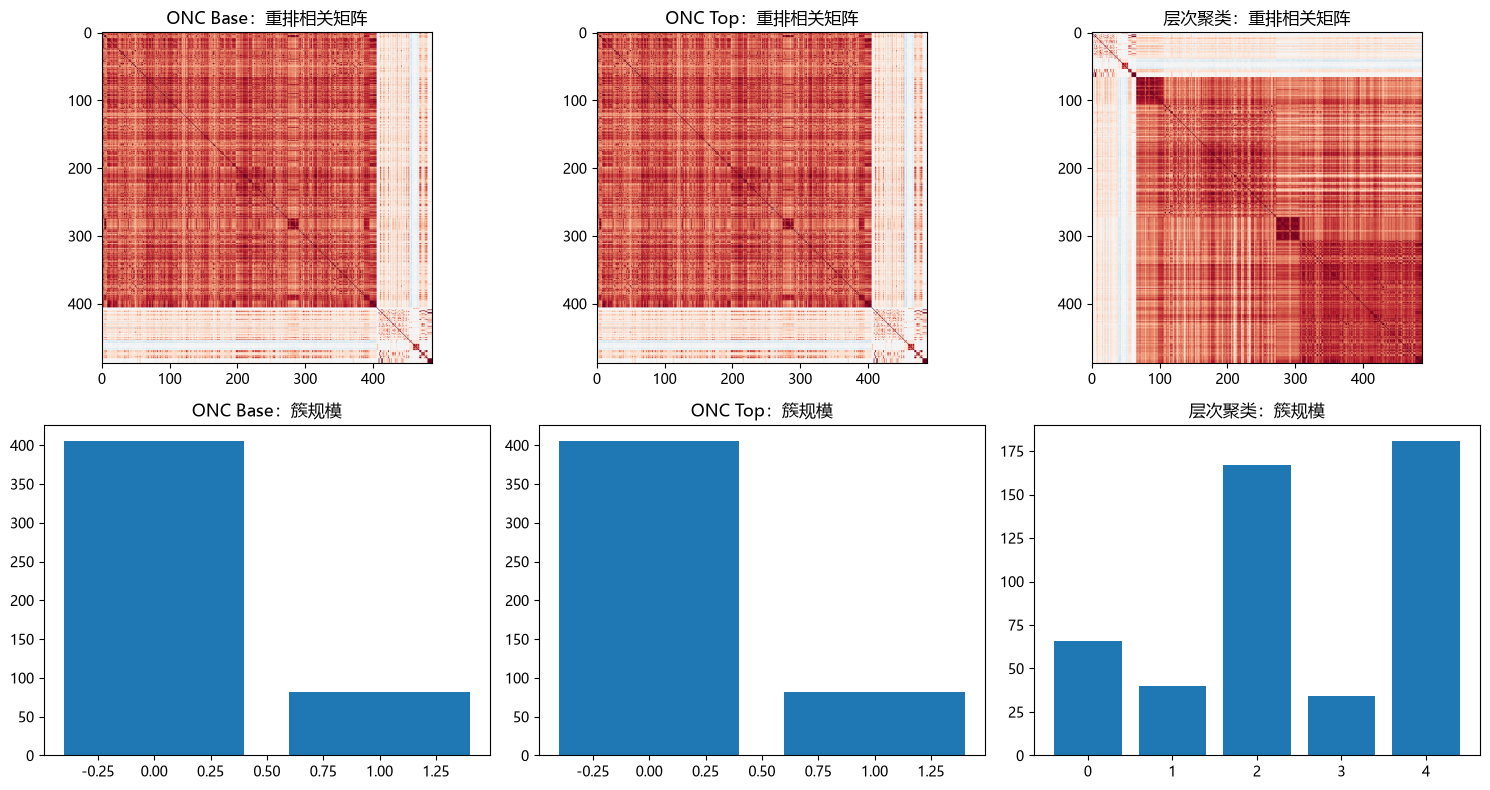

,ONC Base,ONC Top,层次聚类
159001.SZ,1,1,0
159003.SZ,1,1,0
159005.SZ,1,1,0
159703.SZ,0,0,4
159708.SZ,0,0,2
...,...,...,...
588300.SH,0,0,4
588330.SH,0,0,4
588360.SH,0,0,4
588380.SH,0,0,4


In [3]:
ari = pd.DataFrame({a: {b: adjusted_rand_score(la, lb) for b, lb in labels_by_method.items()}
                    for a, la in labels_by_method.items()})
nmi = pd.DataFrame({a: {b: normalized_mutual_info_score(la, lb) for b, lb in labels_by_method.items()}
                    for a, la in labels_by_method.items()})
print('ARI（方法之间的一致性，不是真实准确率）'); display(ari)
print('NMI（方法之间的一致性）'); display(nmi)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, (name, labels) in enumerate(labels_by_method.items()):
    order = np.argsort(labels, kind='stable')
    axes[0, column].imshow(corr.to_numpy()[np.ix_(order, order)], cmap='RdBu_r', vmin=-1, vmax=1)
    axes[0, column].set_title(name + '：重排相关矩阵')
    sizes = pd.Series(labels).value_counts().sort_index()
    axes[1, column].bar(sizes.index, sizes.values)
    axes[1, column].set_title(name + '：簇规模')
plt.tight_layout(); plt.show()
cluster_membership = pd.DataFrame(labels_by_method, index=assets)
display(cluster_membership)

## 2. 可选稳定性实验
保持全资产集合，仅对训练日期做80%无放回抽样，重复3次。稳定性高不保证预测有效；
该步骤多次重跑原ONC，默认关闭。第7章独立重新构建聚类，不依赖本Notebook的变量。

In [4]:
if RUN_EXPENSIVE:
    stability = []
    for repeat in range(3):
        sample = X_train.sample(frac=.8, random_state=SEED+repeat).sort_index()
        np.random.seed(SEED)
        result, seconds = timed(f'稳定性ONC Top {repeat+1}/3', lambda: quiet(lambda:
            original.clusterKMeansTop(sample.corr().clip(-1, 1), maxNumClusters=MAX_CLUSTERS)))
        sample_hc = HierarchicalClustering().fit(PearsonDistance().fit(sample).distance_)
        stability.append({'重复': repeat+1,
                          'ONC与完整训练样本ARI': adjusted_rand_score(labels_by_method['ONC Top'], labels_from_clusters(result[1])),
                          '层次与完整训练样本ARI': adjusted_rand_score(hc.labels_, sample_hc.labels_), 'ONC耗时秒': seconds})
    display(pd.DataFrame(stability))
else:
    print('重复抽样稳定性扩展未执行；上面的主实验为完整训练样本。')

重复抽样稳定性扩展未执行；上面的主实验为完整训练样本。


## 结论阅读
分别看簇数、结构、共同几何空间评分和运行成本。原ONC子空间嵌入存在README所述问题；
层次聚类是替代方法，不是对ONC缺陷的数值等价修补。不得把较高轮廓系数当作更高投资收益。